In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [56]:
# Step 1: Exploratory Data Analysis (EDA) & Data Auditing

In [57]:
# ● Task 1.1: Load the dataset into a Pandas DataFrame and inspect its shape, columns, and data types
df = pd.read_csv("/content/AB_NYC_2019.csv")

In [58]:
df.shape

(48895, 16)

In [59]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [60]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [61]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [62]:
# Task 1.2: Identify which columns are numerical (discrete/continuous) and which are categorical (nominal/ordinal).

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [63]:
#  Task 1.3: Check for missing values across all columns. Write down which columns have missing data and calculate their percentages.

df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [64]:
missing = df.isnull().sum()
missing_summary = pd.DataFrame({
    'Missing Value' : missing,
    'Percentage' :  (missing/len(df)*100).round(2)
})
print(missing_summary[missing_summary['Missing Value'] > 0])


                   Missing Value  Percentage
name                          16        0.03
host_name                     21        0.04
last_review                10052       20.56
reviews_per_month          10052       20.56


In [65]:
# Step 2: Data Cleaning & Handling Missing Values

In [66]:
# Task 2.1: Look at the last_review column. Since it's a date string with
# over 10,000 missing values, decide whether to drop the column entirely
# or engineer it.
df['last_review']


,last_review
0,2018-10-19
1,2019-05-21
2,NaN
3,2019-07-05
4,2018-11-19
...,...
48890,NaN
48891,NaN
48892,NaN
48893,NaN


In [67]:
# Task - 2.1 Engineer Last review , keep the last reviewed year
df['never_reviewed'] = df['last_review'].isnull().astype(int)

df.drop(columns=['last_review'], inplace=True)

In [68]:
# Task - 2.2  logical replacement value.
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [69]:
# Task - 2.3 Drop irrelevant identifier columns
df.drop(columns =['name','id','host_id','host_name'],inplace = True)

In [70]:
# Step 3: Outlier Identification & Treatment


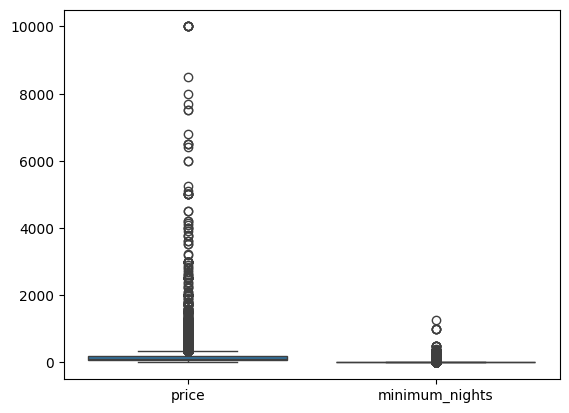

In [71]:
# Task 3.1 Create boxplots or histograms for price and minimum_night
sns.boxplot(df[['price' ,'minimum_nights']])
plt.show()

In [72]:
# Task 3.2  Apply a capping or trimming strategy. Use the 95th percentile
df['price'] = df['price'].clip(lower=df['price'].quantile(0.01), upper=df['price'].quantile(0.95))
df['minimum_nights'] = df['minimum_nights'].clip(lower=df['minimum_nights'].quantile(0.01), upper=df['minimum_nights'].quantile(0.95))

In [73]:
# Step 4: Feature Selection & Categorical Encoding

In [74]:
# Task 4.1: Address High Cardinality.
df.drop(columns=['neighbourhood'], inplace=True)

In [75]:
# Task 4.2  Convert the remaining categorical columns (neighbourhood_group and room_type) into numerical format
df = pd.get_dummies(df,columns=['neighbourhood_group','room_type'],drop_first= True,dtype = int)


 Explanation: neighbourhood has 200+ unique categories. Encoding them can create many features, increasing model complexity and the risk of overfitting. We keep neighbourhood_group, which has only 5 broader categories and captures location information more simply.

In [76]:
df.head()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,never_reviewed,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,0,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,1,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,0,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,0,1,0,0,0,0


In [75]:
# Step 5: Feature-Target Separation & Validation Split

In [77]:
# Task 5.1 : Seperate Variables
X = df.drop(columns=['price'])
Y = df['price']

In [78]:
# Task 5.2 : Train-Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size = 0.2, random_state=42)

In [ ]:
# Step 6: Model Training & Evaluation

In [80]:
# Task 6.1 Import, initialise, and fit a standard Linear Regression model using the training data
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,Y_train)

LinearRegression()

In [81]:
#  Task 6.2: Use the trained model to generate price predictions on the hidden testing data.
Y_pred = model.predict(X_test)

In [83]:
# Task 6.3: Calculate three key metrics to grade the model:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse = mean_squared_error(Y_test,Y_pred)
mae = mean_absolute_error(Y_test,Y_pred)
r2 = r2_score(Y_test,Y_pred)
print("Mean Square Error:", mse)
print("Mean Absolute error:",mae)
print("R2 Score:", r2)

Mean Square Error: 3914.930069200814
Mean Absolute error: 45.6952064166198
R2 Score: 0.4668833806700219


In [ ]:
# Step 7: Residual Analysis & Interpretation

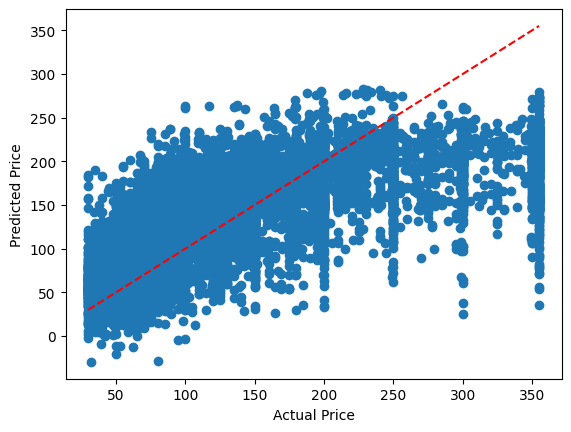

In [84]:
# Task 7.1: Plot a scatter plot of Actual Prices vs. Predicted Prices

plt.scatter(Y_test, Y_pred)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()

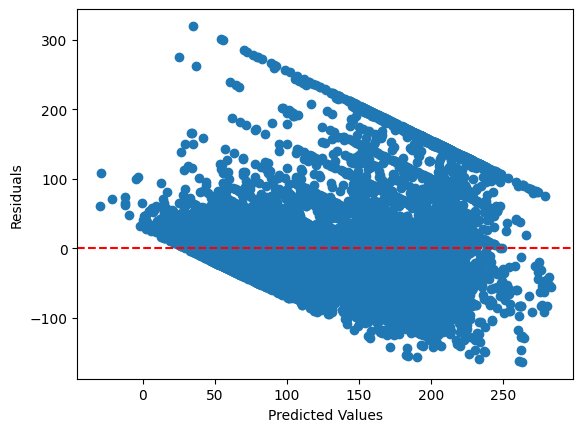

In [86]:
# Task 7.2: Plot a Residual Plot (Errors vs. Predicted values) or an error distribution histogram.
residuals = Y_test - Y_pred
plt.scatter(Y_pred,residuals)
plt.axhline(y=0,color='r',linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.show()


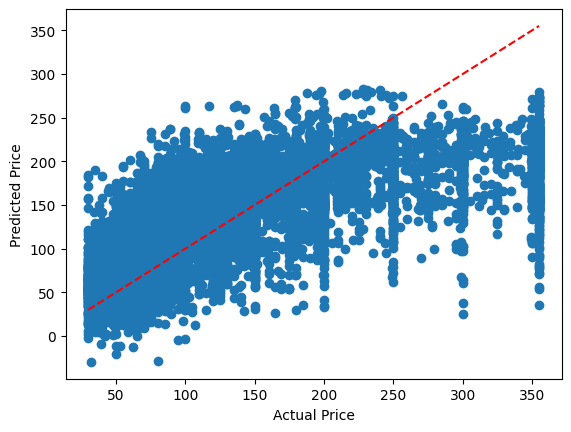

In [87]:
# Task 7.3: Does the model perform better on cheap listings or expensive listings, and why?
plt.scatter(Y_test, Y_pred)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()



The model generally performs better on cheap listings because their prices are more common and less variable. It may make larger errors on expensive listings because these listings have fewer examples and more varied pricing patterns. The scatter plot helps verify this by showing whether expensive listings lie farther from the 45° diagonal line.